# Gray-Scott lab

Train a model on a few trajectories, or on parts of them, and see whether it learned them.

| Question | Call |
|---|---|
| Can a model learn these trajectories? | `res = lab.run(spec, data)`, then `res.table()` and `res.plot()` |
| Which model? | `lab.sweep(base, data, arch=[...])` or a list of specs |
| What if I remove / add this? | `lab.ablate(base, data, {"label": changes})` |
| Does it hold on trajectories it has not seen? | put them in `spec.test` |

A segment is rolled out from its first `history` frames (ground truth) to its end. Its error is measured against **persistence** (holding the last given frame), so a segment in which little happens is not "learned" by predicting that nothing happens.

| Status | Meaning |
|---|---|
| `OK` | right outcome, rollout RMSE below 0.1 x persistence RMSE |
| `DRIFT` | right outcome, error above that |
| `WRONG` | the last frame is in another class (pattern / uniform / extinct) |
| `DIVERGED` | a prediction exceeded 10 in absolute value |

The outputs below were produced on 2 CPU cores with the budgets set in the first cell: about 3 minutes per conv-net experiment, and a short run for Walrus that shows the pipeline rather than an answer. Raise `STEPS` and `WALRUS_STEPS` on a GPU.

In [1]:
import pandas as pd
import torch

from grayscott import lab

pd.options.display.float_format = "{:.3g}".format

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STEPS = 1000         # training steps per conv-net experiment
WALRUS_STEPS = 150   # short run on CPU; use thousands on a GPU
SIZE = 64            # grid side. Walrus needs 128 (section 5)
FRAME_DT = 5         # time between frames. 20 = the earlier experiments: patterns form, but a collapse lasts ~15 frames
N_FRAMES = 160
print(DEVICE, torch.get_num_threads(), "threads")

cpu 2 threads


## 1. Trajectories

The six presets, plus three simulated here. `data.add(name, F, k, amp, seed)` runs the simulator; a trajectory whose B field dies out gets a `collapse` part (from the peak of mean B until nothing changes any more, plus 4 frames).

Selections are strings: `"extinct"` (whole trajectory), `"extinct:collapse"`, `"spots:0-60"` (frames 0 to 59). Parts: `all`, `active`, `collapse`, `steady`.

In [2]:
data = lab.Data.standard(SIZE, N_FRAMES, FRAME_DT)
data.add("weak", F=0.030, k=0.062, amp=0.4, seed=11)    # another sub-threshold collapse, same (F, k) as spots
data.add("dying", F=0.045, k=0.068, amp=1.0, seed=21)   # another parameter-driven collapse, unseen (F, k)
data.add("strong", F=0.030, k=0.062, amp=0.8, seed=1)   # same bump layout as subthreshold, above threshold: it survives
data.table()

,name,F,k,amp,outcome,all,active,steady,collapse
0,spots,0.03,0.062,1,pattern,0-160,0-160,,
1,subthreshold,0.03,0.062,0.6,extinct,0-160,0-62,58-160,0-62
2,maze,0.029,0.057,1,pattern,0-160,0-160,,
3,solitons,0.03,0.07,1,pattern,0-160,0-160,,
4,uniform,0.04,0.045,1,uniform,0-160,0-138,134-160,
5,extinct,0.05,0.068,1,extinct,0-160,0-46,42-160,0-46
6,weak,0.03,0.062,0.4,extinct,0-160,0-58,54-160,0-58
7,dying,0.045,0.068,1,extinct,0-160,0-52,48-160,0-52
8,strong,0.03,0.062,0.8,pattern,0-160,0-160,,


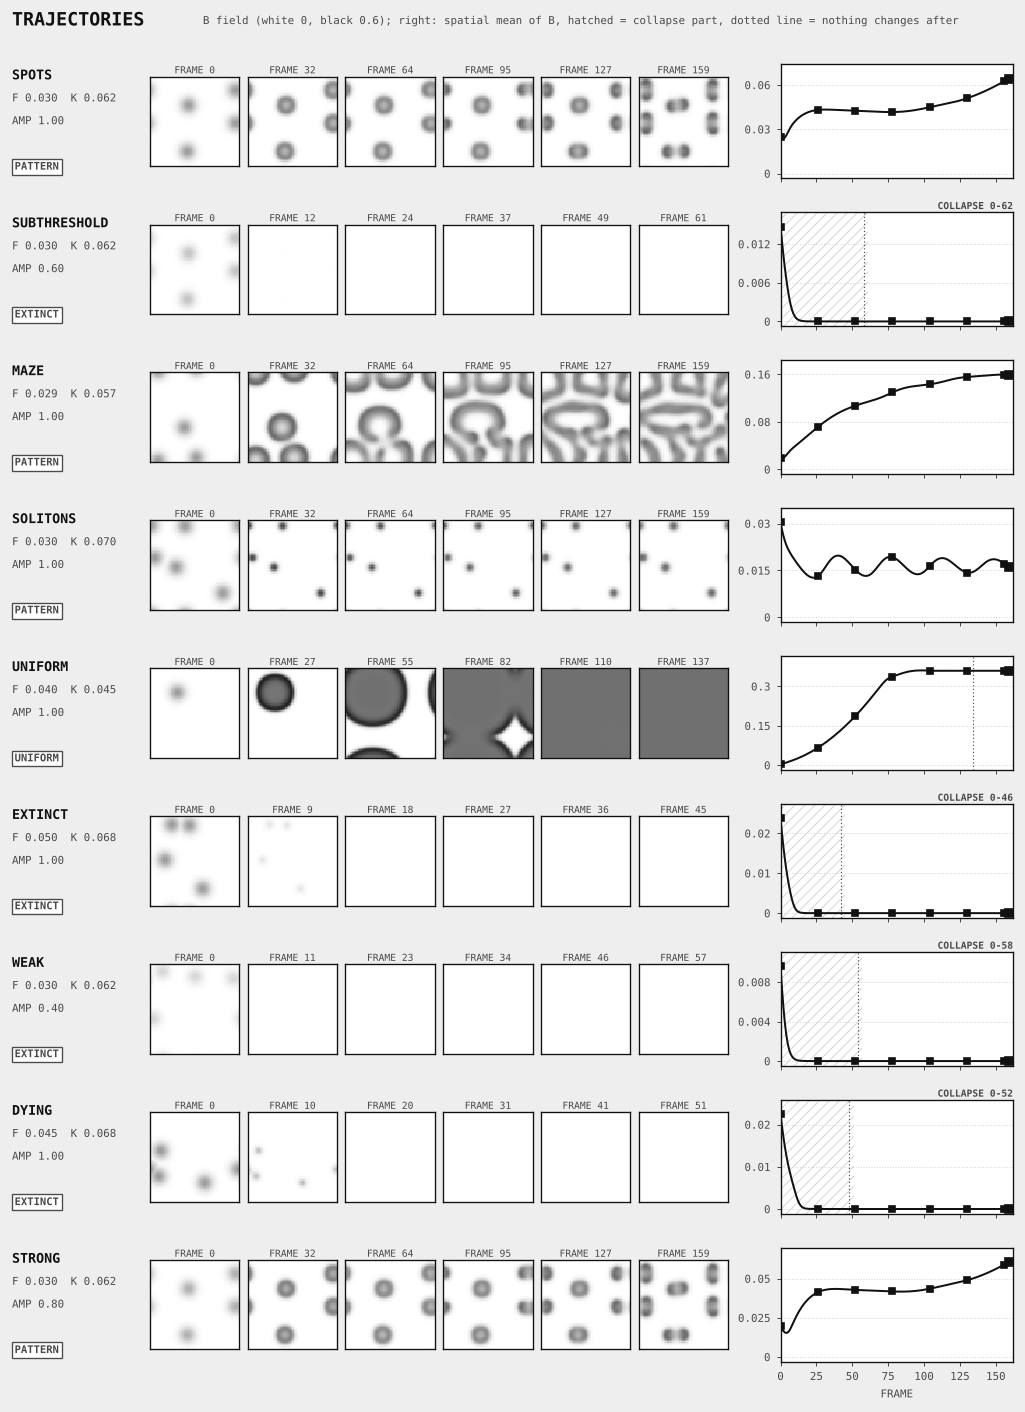

In [3]:
data.show()

## 2. Can a model learn the collapses?

Train on the collapse part of two trajectories. Held out: two other collapses, and `strong`, which starts from the same layout as `subthreshold` but survives.

In [4]:
base = lab.Spec(
    arch="resnet",              # resnet | unet | fno | walrus
    norm="global-meanstd",      # window-rms (Walrus) | window-meanstd | global-rms | global-meanstd | none
    cond="none",                # none | scales (feed the window statistics) | params (feed F, k)
    clip=True,                  # project the state fed back on bounds detected in the training selection
    history=4,
    train=["subthreshold:collapse", "extinct:collapse"],
    test=["weak:collapse", "dying:collapse", "strong:0-62"],
    steps=STEPS,
)
res = lab.run(base, data, device=DEVICE)
res.table()

resnet / global-meanstd: 76,386 parameters, 100 training samples from 2 segments, 1000 steps
  step    200  loss 0.2093  0.5 min
  step    400  loss 0.0322  0.9 min
  step    600  loss 0.0167  1.4 min
  step    800  loss 0.0079  1.9 min
  step   1000  loss 0.0018  2.3 min
  resnet / global-meanstd: learned 2/2 training segments, 2/3 held-out segments (right outcome, rollout error below 0.1 x persistence)


,split,selection,frames,status,rel_rmse,rmse,persistence_rmse,one_step_err,outcome,truth
0,train,subthreshold:collapse,0-62,OK,0.017,0.000682,0.04,0.0582,extinct,extinct
1,train,extinct:collapse,0-46,OK,0.0095,0.000598,0.0629,0.0352,extinct,extinct
2,test,weak:collapse,0-58,OK,0.0461,0.000986,0.0214,0.0678,extinct,extinct
3,test,dying:collapse,0-52,OK,0.0515,0.00351,0.0681,0.125,extinct,extinct
4,test,strong:0-62,0-62,WRONG,1.56,0.163,0.104,1.95,extinct,pattern


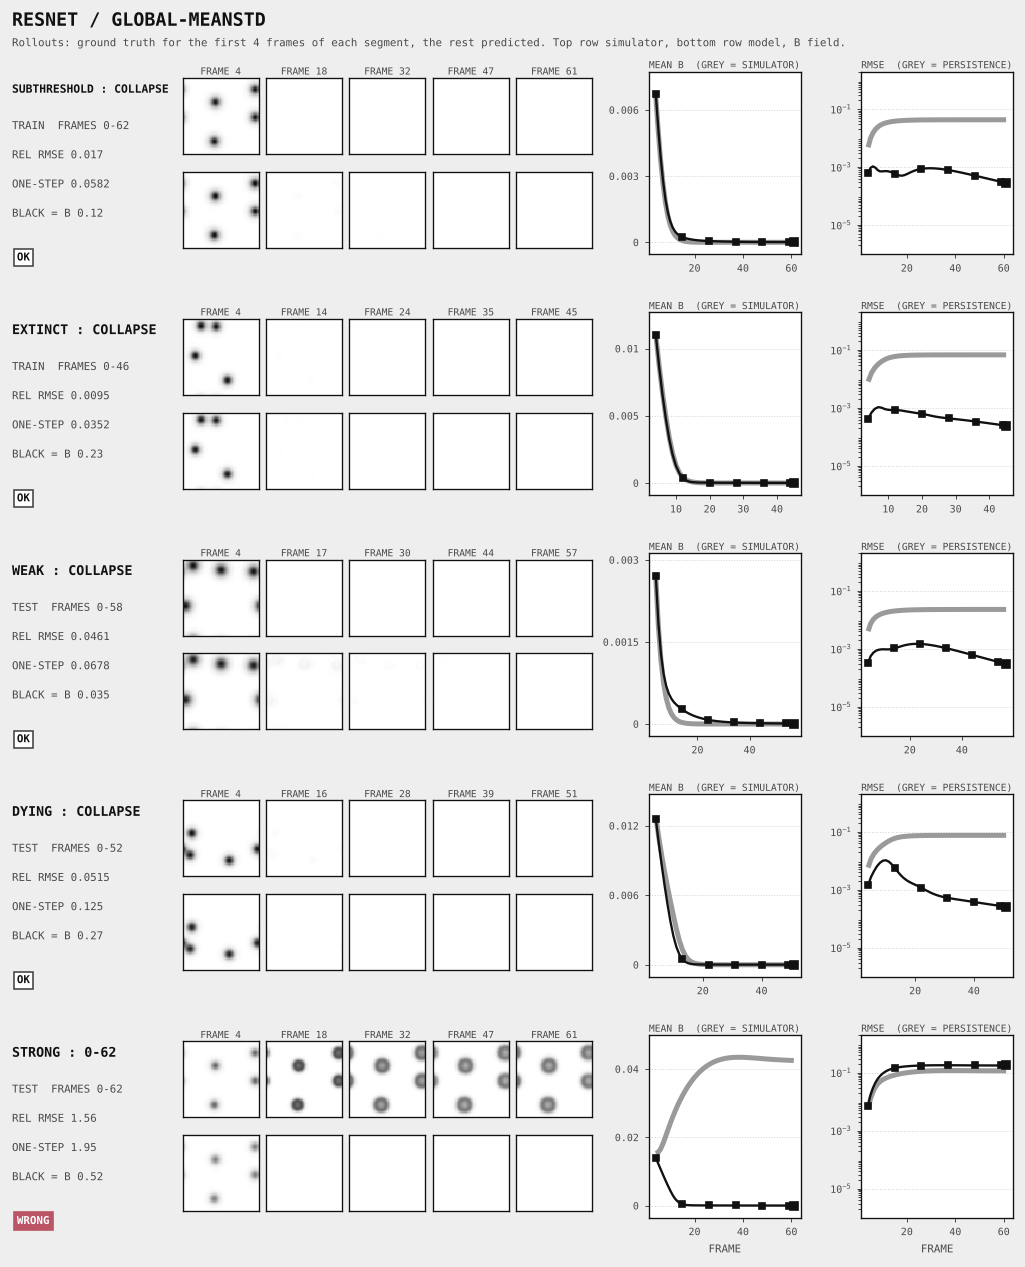

In [5]:
res.plot()

## 3. Which model?

Same data, same normalisation, three networks. The U-Net and the FNO are compact periodic implementations in `grayscott/nets.py`, not The Well's benchmark classes.

unet: 626,018 parameters, 100 training samples from 2 segments, 1000 steps
  step    200  loss 0.2024  0.6 min
  step    400  loss 0.0377  1.2 min
  step    600  loss 0.0187  1.8 min
  step    800  loss 0.0048  2.3 min
  step   1000  loss 0.0013  2.9 min
  unet: learned 2/2 training segments, 2/3 held-out segments (right outcome, rollout error below 0.1 x persistence)
fno: 1,186,402 parameters, 100 training samples from 2 segments, 1000 steps
  step    200  loss 0.1840  0.3 min
  step    400  loss 0.0071  0.7 min
  step    600  loss 0.0011  1.0 min
  step    800  loss 0.0001  1.4 min
  step   1000  loss 0.0001  1.7 min
  fno: learned 2/2 training segments, 2/3 held-out segments (right outcome, rollout error below 0.1 x persistence)


,experiment,params,steps,minutes,final_loss,train_ok,train_one_step,train_rel_rmse,test_ok,test_rel_rmse
0,resnet / global-meanstd,76386,1000,2.3,0.00181,2/2,0.0467,0.0133,2/3,0.553
1,unet,626018,1000,2.9,0.0013,2/2,0.0377,0.0126,2/3,0.558
2,fno,1186402,1000,1.7,9.48e-05,2/2,0.0105,0.00238,2/3,0.574


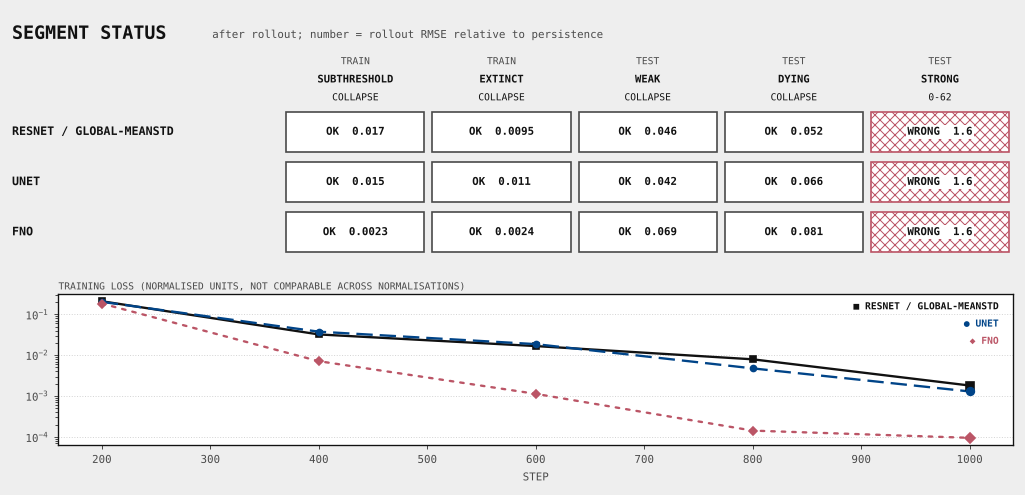

In [6]:
specs = [
    base.but("unet", arch="unet", blocks=2),                     # blocks = number of downsamplings
    base.but("fno", arch="fno", arch_kwargs={"modes": 12}),
]
zoo = [res] + [lab.run(s, data, device=DEVICE) for s in specs]
lab.compare(zoo)

## 4. What if I remove or add this?

`lab.ablate` trains the base once (here it reuses `res`) and then one variant per entry. A variant is a dict of changes to the spec: a model setting, or another training / test selection. Switching only `clip` costs nothing: with a single-step loss the projection does not enter training, so the base model is rolled out again.

- clip: same model as the base, rolled out with clip=False
  - clip: learned 2/2 training segments, 2/3 held-out segments (right outcome, rollout error below 0.1 x persistence)
norm = window-rms: 76,386 parameters, 100 training samples from 2 segments, 1000 steps
  step    200  loss 0.1041  0.5 min
  step    400  loss 0.0593  1.0 min
  step    600  loss 0.0522  1.4 min
  step    800  loss 0.0504  1.9 min
  step   1000  loss 0.0469  2.4 min
  norm = window-rms: learned 1/2 training segments, 2/3 held-out segments (right outcome, rollout error below 0.1 x persistence)
window-rms + scales: 93,346 parameters, 100 training samples from 2 segments, 1000 steps
  step    200  loss 0.0932  0.5 min
  step    400  loss 0.0425  1.0 min
  step    600  loss 0.0324  1.5 min
  step    800  loss 0.0265  2.0 min
  step   1000  loss 0.0228  2.4 min
  window-rms + scales: learned 1/2 training segments, 1/3 held-out segments (right outcome, rollout error below 0.1 x persistence)
+ (F, k) input: 93,218 para

,experiment,params,steps,minutes,final_loss,train_ok,train_one_step,train_rel_rmse,test_ok,test_rel_rmse
0,resnet / global-meanstd,76386,1000,2.3,0.00181,2/2,0.0467,0.0133,2/3,0.553
1,- clip,76386,1000,2.3,0.00181,2/2,0.0467,0.0215,2/3,0.573
2,norm = window-rms,76386,1000,2.4,0.0469,1/2,0.233,0.0842,2/3,0.56
3,window-rms + scales,93346,1000,2.4,0.0228,1/2,0.123,0.0841,1/3,0.59
4,"+ (F, k) input",93218,1000,2.4,0.00198,2/2,0.0439,0.0115,2/3,0.553
5,- extinct,76386,1000,2.2,0.000463,1/1,0.0229,0.00648,3/4,0.427
6,+ strong (a survivor),76386,1000,2.3,0.00572,2/3,0.0651,0.1,0/2,0.133


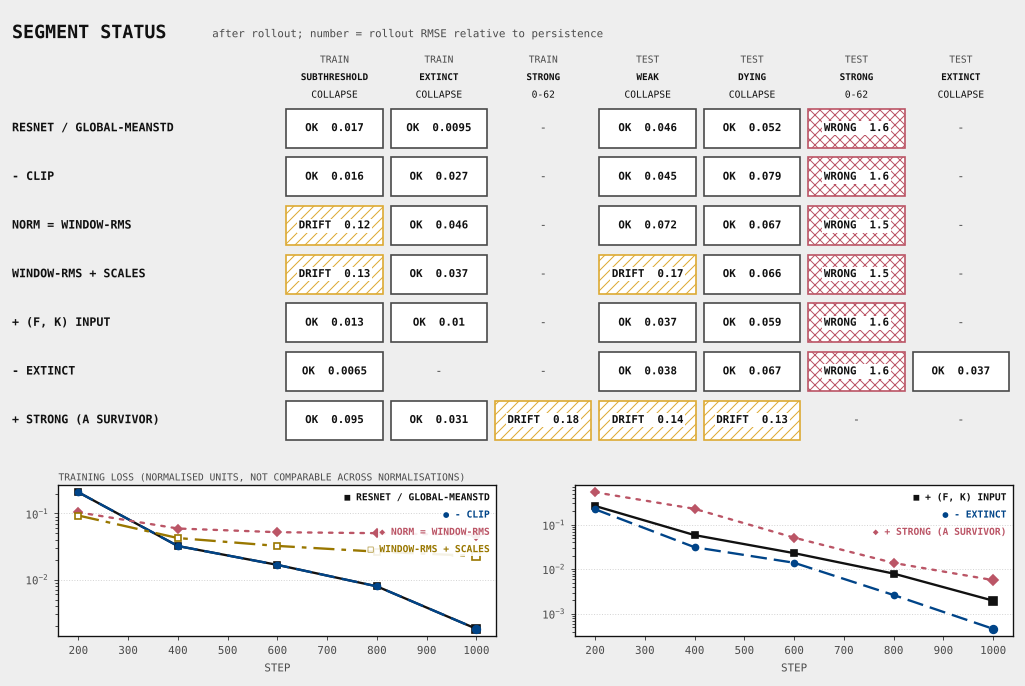

In [7]:
variants = {
    "- clip":                    dict(clip=False),
    "norm = window-rms":         dict(norm="window-rms"),                    # the released Walrus normalisation
    "window-rms + scales":       dict(norm="window-rms", cond="scales"),    # ... and tell the network the window statistics
    "+ (F, k) input":            dict(cond="params"),
    "- extinct":                 dict(train=["subthreshold:collapse"], test=base.test + ["extinct:collapse"]),
    "+ strong (a survivor)":     dict(train=base.train + ["strong:0-62"], test=["weak:collapse", "dying:collapse"]),
}
abl = lab.ablate(base, data, variants, device=DEVICE, baseline=res)
lab.compare(abl)

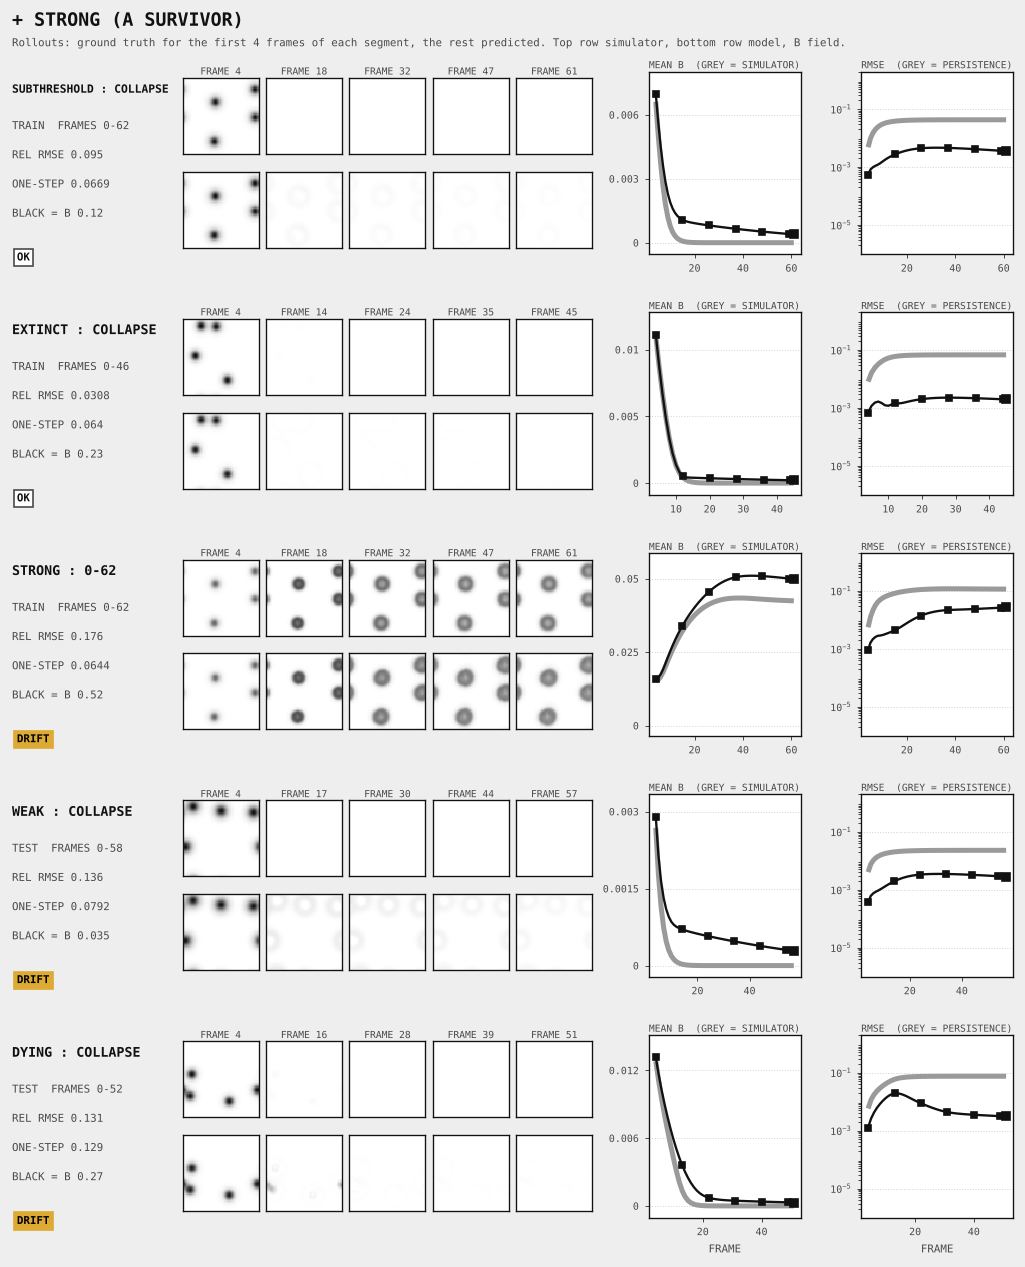

In [8]:
abl[-1].plot()   # the model that also saw a survivor

## 5. Walrus, and Walrus with other normalisations

`arch="walrus"` builds the official architecture (`walrus.models.IsotropicModel`, same encoder, processor and decoder classes as the released checkpoint) at the size given by `arch_kwargs["size"]`: `tiny` (1.9M parameters), `small`, `base`, or `released` (1.3B). It is trained here from scratch, on its prediction at every input frame, as the Walrus trainer does. `norm` picks one of the four strategies of the Walrus code base; `window-rms` is the one the released model uses, with an L1 loss and 6 input frames on Gray-Scott.

Walrus tokenises to 32 tokens per axis and has no patch size for a 64-pixel side, so this section uses 128 x 128 trajectories (the size of The Well's Gray-Scott data), with 4 times as many seeds. Patch jittering stays on at inference, as in the paper, so Walrus rollouts are stochastic; pass `arch_kwargs={"size": "tiny", "jitter": False}` to turn it off.

In [9]:
data128 = lab.Data(128, N_FRAMES, FRAME_DT)
data128.add("subthreshold", F=0.030, k=0.062, amp=0.6, seed=1, n_seeds=16)
data128.add("extinct", F=0.050, k=0.068, amp=1.0, seed=3, n_seeds=16)
data128.add("spots", F=0.030, k=0.062, amp=1.0, seed=1, n_seeds=16)

walrus = lab.Spec(
    name="walrus / window-rms",
    arch="walrus", arch_kwargs={"size": "tiny"},
    norm="window-rms", loss="l1", history=6, clip=False,
    train=["subthreshold:collapse", "extinct:collapse"],
    test=["spots:0-46"],
    steps=WALRUS_STEPS, batch=2,
)
w = lab.run(walrus, data128, device=DEVICE)
w.table()

walrus / window-rms: 1,932,939 parameters, 97 training samples from 2 segments, 150 steps
  step     30  loss 0.2325  0.5 min
  step     60  loss 0.1837  1.0 min
  step     90  loss 0.1732  1.6 min
  step    120  loss 0.1571  2.1 min
  step    150  loss 0.1477  2.6 min
  walrus / window-rms: learned 0/2 training segments, 0/1 held-out segments (right outcome, rollout error below 0.1 x persistence)


,split,selection,frames,status,rel_rmse,rmse,persistence_rmse,one_step_err,outcome,truth
0,train,subthreshold:collapse,0-63,WRONG,0.489,0.0156,0.0318,0.457,pattern,extinct
1,train,extinct:collapse,0-46,WRONG,0.611,0.03,0.0491,0.479,pattern,extinct
2,test,spots:0-46,0-46,DRIFT,2.04,0.143,0.0699,1.57,pattern,pattern


walrus / window-meanstd: 1,932,939 parameters, 97 training samples from 2 segments, 150 steps
  step     30  loss 0.2771  0.5 min
  step     60  loss 0.1788  1.1 min
  step     90  loss 0.1474  1.6 min
  step    120  loss 0.1449  2.2 min
  step    150  loss 0.1092  2.7 min
  walrus / window-meanstd: learned 0/2 training segments, 0/1 held-out segments (right outcome, rollout error below 0.1 x persistence)
walrus / global-rms: 1,932,939 parameters, 97 training samples from 2 segments, 150 steps
  step     30  loss 0.2350  0.6 min
  step     60  loss 0.1572  1.1 min
  step     90  loss 0.1346  1.7 min
  step    120  loss 0.1537  2.2 min
  step    150  loss 0.0878  2.8 min
  walrus / global-rms: learned 0/2 training segments, 0/1 held-out segments (right outcome, rollout error below 0.1 x persistence)
walrus / global-meanstd: 1,932,939 parameters, 97 training samples from 2 segments, 150 steps
  step     30  loss 0.2437  0.6 min
  step     60  loss 0.1167  1.1 min
  step     90  loss 0.07

,experiment,params,steps,minutes,final_loss,train_ok,train_one_step,train_rel_rmse,test_ok,test_rel_rmse
0,walrus / window-rms,1932939,150,2.6,0.148,0/2,0.468,0.55,0/1,2.04
1,walrus / window-meanstd,1932939,150,2.7,0.109,0/2,0.344,0.45,0/1,2.14
2,walrus / global-rms,1932939,150,2.8,0.0878,0/2,0.617,0.433,0/1,1.57
3,walrus / global-meanstd,1932939,150,2.8,0.0547,0/2,0.385,0.188,0/1,1.93


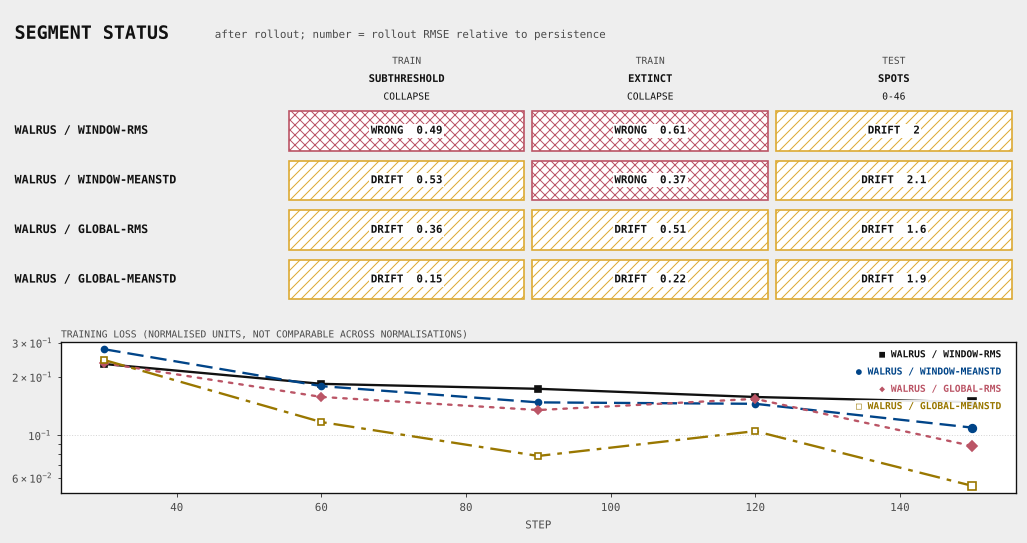

In [10]:
norms = ["window-meanstd", "global-rms", "global-meanstd"]
w_norms = [w] + [lab.run(walrus.but(f"walrus / {n}", norm=n), data128, device=DEVICE) for n in norms]
lab.compare(w_norms)

**Released weights.** Download `walrus.pt` from `huggingface.co/polymathic-ai/walrus`, then

```python
released = walrus.but("walrus released", arch_kwargs={"size": "released", "weights": "checkpoints/walrus.pt"}, lr=1e-5)
lab.run(released, data128, device="cuda")
```

The two fields are then embedded as Gray-Scott's `A` and `B` (indices 42 and 43 of the released field map). This path follows the official demo notebook but has not been run here: no GPU and no access to the weights. With `steps=0` it evaluates the released model as is.

## 6. Your own question

```python
# another trajectory, another part
data.add("mine", F=0.035, k=0.066, amp=1.0, seed=5)
data.parts("mine")                                  # which named parts it has
spec = base.but("mine", train=["mine:collapse", "extinct:10-40"])

# a model setting
base.but(norm="none")                               # no normalisation at all
base.but(arch="unet", arch_kwargs={"inner_norm": "group"})   # GroupNorm inside the network
base.but(history=2, unroll=4)                       # shorter input, 4 autoregressive steps in the loss
base.but(extra={"eps": 1e-8})                       # any field of grayscott.model.Config

# several at once
lab.sweep(base, data, arch=["resnet", "fno"], norm=["window-rms", "global-meanstd"])

# keep a model
lab.save(res, "runs/lab/base.pt")
```

`tol` in `lab.run(..., tol=0.1)` moves the line between `OK` and `DRIFT`. Statistics for the `global-*` normalisations and the detected bounds come from the training selection only (`res.stats`).